# Lab 11: Attention

**Student Name:** Danyal Salman Alhashem  
**Student ID:** 2240002713


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
# Put the CSV file in the same folder as this notebook
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences
except ImportError:
    # TensorFlow not installed: a small replacement that works the same way
    import numpy as np
    FILTERS = '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'

    def _words(text):
        text = text.lower().translate(str.maketrans({ch: " " for ch in FILTERS}))
        return [w for w in text.split(" ") if w]

    class Tokenizer:
        def fit_on_texts(self, texts):
            counts = {}
            for t in texts:
                for w in _words(t):
                    counts[w] = counts.get(w, 0) + 1
            ordered = sorted(counts.items(), key=lambda kv: kv[1], reverse=True)
            self.word_index = {w: i + 1 for i, (w, _) in enumerate(ordered)}
            self.index_word = {i: w for w, i in self.word_index.items()}

        def texts_to_sequences(self, texts):
            return [[self.word_index[w] for w in _words(t) if w in self.word_index] for t in texts]

    def pad_sequences(seqs, padding="pre"):
        n = max(len(s) for s in seqs)
        out = np.zeros((len(seqs), n), dtype="int64")
        for i, s in enumerate(seqs):
            if padding == "post":
                out[i, :len(s)] = s
            else:
                out[i, n - len(s):] = s
        return out

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

> **Note on two fixes in the given code**
>
> 1. `nn.RNN` expects input shaped *(sequence, batch, features)* by default, but `X` is *(batch, sequence)*. Without `batch_first=True`, the RNN was reading across the 168 questions instead of across the words of one question, so the attention weights were not really about the words of a question.
> 2. The training loop had no `optimizer.zero_grad()`, so gradients from every epoch were summed together.
>
> Both are one-line fixes; the rest of the lab is unchanged.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        # FIX: batch_first=True so the RNN reads the words of each question in order
        # (without it, PyTorch treats dim 0 = the 168 questions as the time steps)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))                 # (batch, words, 32)
        weights = torch.softmax(self.att(x), dim=1)  # one weight per word, sums to 1
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() # FIX: clear old gradients, otherwise they keep adding up every epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

accuracy = (model(X)[0].argmax(1) == y).float().mean().item()
print("Training finished!  Final loss: %.3f  |  Training accuracy: %.1f%%" % (loss.item(), accuracy * 100))

Training finished!  Final loss: 0.097  |  Training accuracy: 98.2%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

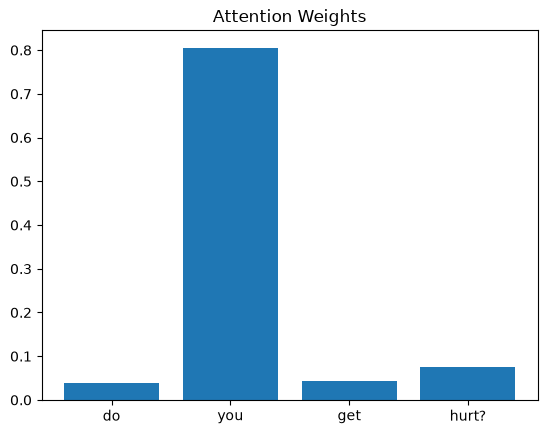

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Q0: "do you get hurt?"  ->  highest attention: "you" (0.80)
Q15: "are we the same age?"  ->  highest attention: "the" (0.54)
Q99: "do you ever eat beef?"  ->  highest attention: "eat" (0.92)


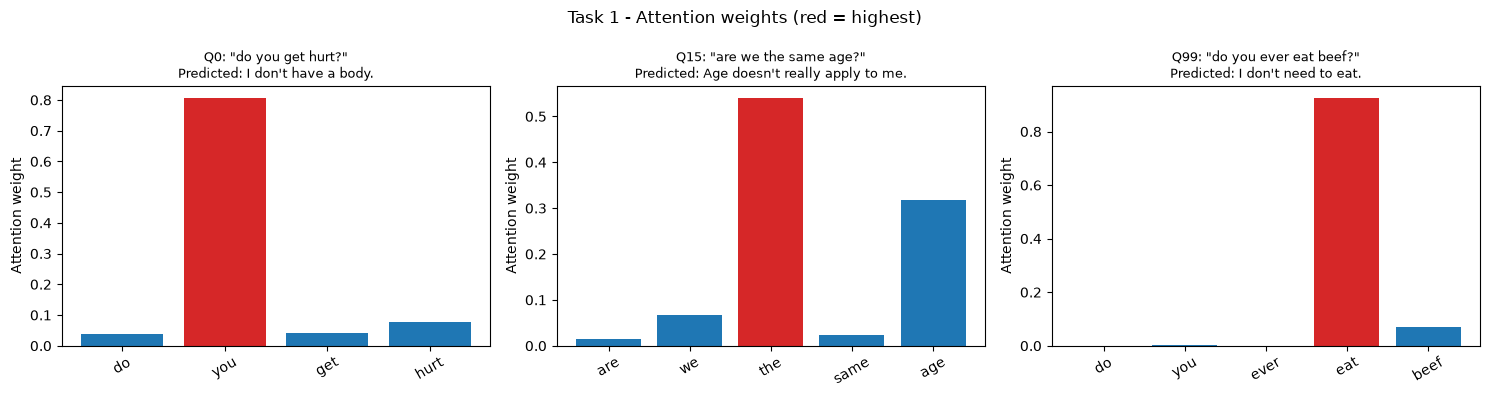

In [7]:
def get_attention(i):
    """Run question number i through the trained model.
    Returns the cleaned words, their attention weights, and the predicted answer."""
    ids = X[i][X[i] != 0].tolist()                        # drop the padding zeros
    words = [tokenizer.index_word[t] for t in ids]       # the exact words the model saw
    with torch.no_grad():
        logits, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()
    pred = df[df["answer_id"] == logits.argmax(1).item()]["answer"].iloc[0]
    return words, w, pred

def plot_attention(ax, i):
    words, w, pred = get_attention(i)
    top = max(range(len(w)), key=lambda k: w[k])
    colors = ["tab:red" if k == top else "tab:blue" for k in range(len(w))]
    ax.bar(words, w, color=colors)
    ax.set_title(f'Q{i}: "{df["question"][i]}"\nPredicted: {pred}', fontsize=9)
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=30)
    return words[top], w[top]

# Task 1: three questions from three different answer groups
task1 = [0, 15, 99]   # body / age / food

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, i in zip(axes, task1):
    word, value = plot_attention(ax, i)
    print(f'Q{i}: "{df["question"][i]}"  ->  highest attention: "{word}" ({value:.2f})')
plt.suptitle("Task 1 - Attention weights (red = highest)")
plt.tight_layout()
plt.show()

### Task 1 — Answer

| Question | Word with highest attention | Weight | Predicted answer |
|---|---|---|---|
| do you get hurt? | **you** | 0.80 | I don't have a body. ✔ |
| are we the same age? | **the** | 0.54 (2nd: **age** 0.32) | Age doesn't really apply to me. ✔ |
| do you ever eat beef? | **eat** | 0.92 | I don't need to eat. ✔ |

**Do the highest-weighted words look important?** Partly.

- In *"do you ever eat beef?"* the model put almost all its attention (0.92) on **eat**, which is exactly the word that decides the answer group (food). This is a clear case where attention matches human intuition.
- In *"are we the same age?"* the top word is **the**, which by itself means nothing, but the second highest is **age** (0.32), the real keyword. Together they hold most of the weight, so the model still found the important part of the sentence.
- In *"do you get hurt?"* the top word is **you**, not *hurt*. This looks wrong at first, but the attention is applied to the **RNN hidden states**, not to the raw words. The hidden state at a position carries information about the words before it, so a high weight on one position does not always mean that *single word* is the important one.

**Observation:** attention often lands on the meaningful keyword (*eat*, *age*), but it is not a perfect explanation of the model, because each bar represents a word *plus its context* inside the RNN. The model also predicted the correct answer for all three questions, so it uses the weighted information correctly even when the top bar is a small word.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Q24: "how old are you?"  ->  highest attention: "how" (0.31)
Q20: "what's your age?"  ->  highest attention: "age" (0.53)


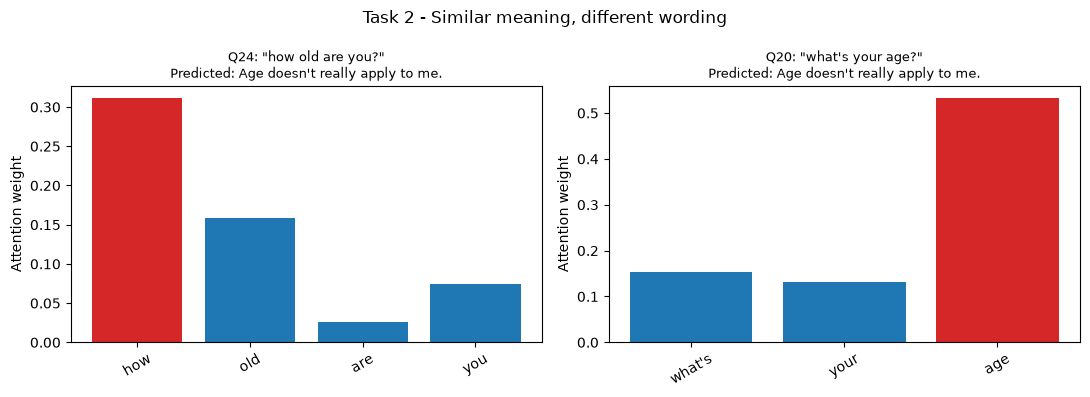

In [8]:
# Task 2: two questions with the same meaning but different wording
# both ask "how old are you?" and both belong to answer group 1 (age)
task2 = [24, 20]   # "how old are you?"  vs  "what's your age?"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, i in zip(axes, task2):
    word, value = plot_attention(ax, i)
    print(f'Q{i}: "{df["question"][i]}"  ->  highest attention: "{word}" ({value:.2f})')
plt.suptitle("Task 2 - Similar meaning, different wording")
plt.tight_layout()
plt.show()

### Task 2 — Answer

Both questions ask the same thing (*"how old are you?"* and *"what's your age?"*) and both belong to answer group 1.

| Question | Highest attention | Other notable words | Predicted answer |
|---|---|---|---|
| how old are you? | **how** (0.31) | old (0.16) | Age doesn't really apply to me. ✔ |
| what's your age? | **age** (0.53) | what's (0.15), your (0.13) | Age doesn't really apply to me. ✔ |

**Similar or different words?** Different words. In the second question the model focuses strongly on **age**. In the first question there is no word *age*, so the attention moves to **how** and **old** — the pair *"how old"* is what carries the age meaning in that sentence.

(The weights shown for *"how old are you?"* add up to less than 1 because part of the attention also went to the padding zeros at the end of the short question.)

**What this suggests about attention:** attention does not search for one fixed keyword. For each sentence it learns *which positions carry the meaning that matters for the task* and gives them more weight. Different wording leads to different focus words, but both paths lead to the same answer. This is the main strength of attention: the model can handle many ways of asking the same question because it adapts its focus to each input instead of treating all words equally.

## What I learned from this lab

1. **What attention is:** a small layer that gives every word a score, turns the scores into weights with softmax (they add up to 1), and builds a weighted sum of the RNN outputs. Instead of using only the last hidden state, the model can look back at every word and decide which ones matter most.
2. **The full pipeline of a simple NLP model:** lowercasing → tokenizing (word → number) → padding to the same length → embedding (number → vector) → RNN (reads words in order) → attention → output layer that picks one of 12 answers.
3. **Attention makes the model easier to interpret.** By plotting the weights as bar charts I could see what the model was focusing on, e.g. *eat* in a food question and *age* in an age question.
4. **Attention is a hint, not a full explanation.** Sometimes small words like *the* or *you* got the highest weight, because the weights are on RNN hidden states that already mix in earlier words. I learned to read the charts carefully and not assume the top bar is always the keyword.
5. **Questions with the same meaning can be understood through different words.** *"how old are you?"* and *"what's your age?"* got the same answer while the model focused on different words in each one.
6. **Small code details matter a lot.** I found that `nn.RNN` needs `batch_first=True` for data shaped *(batch, words)*, and that `optimizer.zero_grad()` is required in every training step. After fixing both, the model reached about 98% training accuracy. Checking tensor shapes is an important habit in PyTorch.
7. **Padding affects attention.** Some attention went to the padding zeros. In a better model, padding positions should be masked so they get zero weight.

---
**Danyal Salman Alhashem — 2240002713**